# Laboratorio 4: Segmentación de imágenes

En este laboratorio usamos K-means para separar lesiones de la piel en imágenes dermatoscópicas. Representamos cada píxel con su color y posición, comparamos distintas configuraciones y evaluamos las máscaras con imágenes de referencia. Al final verificamos una recomendación de IA y exploramos PCA y Mean Shift.

## 1. Preparación de los datos

Importamos las librerías y definimos la ruta del conjunto de datos.


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, f1_score, v_measure_score

RUTA_DATOS = Path("datos")

### Revisión de archivos


In [24]:
def verificar_datos(conjunto):
    ruta = RUTA_DATOS / conjunto

    imagenes = sorted((ruta / "imagenes").glob("*.jpg"))
    mascaras = sorted((ruta / "mascaras").glob("*.png"))

    ids_imagenes = {p.stem for p in imagenes}
    ids_mascaras = {
        p.stem.replace("_Segmentation", "")
        for p in mascaras
    }

    print(f"{conjunto.upper()}")
    print(f"Imágenes: {len(imagenes)}")
    print(f"Máscaras: {len(mascaras)}")
    print(f"Parejas completas: {len(ids_imagenes & ids_mascaras)}")
    print(f"Imágenes sin máscara: {ids_imagenes - ids_mascaras}")
    print(f"Máscaras sin imagen: {ids_mascaras - ids_imagenes}")

verificar_datos("ajuste")
verificar_datos("prueba")

AJUSTE
Imágenes: 15
Máscaras: 15
Parejas completas: 15
Imágenes sin máscara: set()
Máscaras sin imagen: set()
PRUEBA
Imágenes: 5
Máscaras: 5
Parejas completas: 5
Imágenes sin máscara: set()
Máscaras sin imagen: set()


Comprobamos que cada imagen tenga su máscara de referencia y que no falten archivos.


### Carga y visualización

Cargamos las imágenes y sus máscaras a 128 × 128 píxeles para trabajar con el mismo tamaño.


In [25]:

def cargar_imagen(id_imagen, conjunto="ajuste", tamaño=(128, 128)):
    ruta = RUTA_DATOS / conjunto

    ruta_imagen = ruta / "imagenes" / f"{id_imagen}.jpg"
    ruta_mascara = ruta / "mascaras" / f"{id_imagen}_Segmentation.png"

    # Cargar imagen y convertir a RGB
    imagen = Image.open(ruta_imagen).convert("RGB")
    imagen = imagen.resize(tamaño, Image.Resampling.BILINEAR)

    # Cargar máscara y conservar sus valores binarios
    mascara = Image.open(ruta_mascara).convert("L")
    mascara = mascara.resize(tamaño, Image.Resampling.NEAREST)

    imagen = np.array(imagen)
    mascara = (np.array(mascara) > 127).astype(np.uint8)

    return imagen, mascara


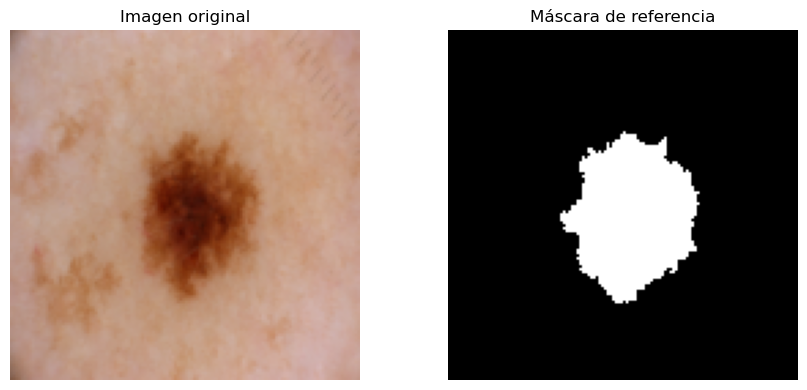

Dimensiones imagen: (128, 128, 3)
Dimensiones máscara: (128, 128)
Valores de máscara: [0 1]


In [26]:

imagen, mascara = cargar_imagen("ISIC_0000085")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(imagen)
axes[0].set_title("Imagen original")

axes[1].imshow(mascara, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Máscara de referencia")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Dimensiones imagen:", imagen.shape)
print("Dimensiones máscara:", mascara.shape)
print("Valores de máscara:", np.unique(mascara))


### Representación de los píxeles

Cada píxel se representa como [βR, βG, βB, λx, λy]. Normalizamos el color y las coordenadas entre 0 y 1. β controla el peso del color y λ el de la posición.


In [27]:

class RepresentacionPixeles(BaseEstimator, TransformerMixin):

    def __init__(self, beta=1.0, lambda_=0.5):
        self.beta = beta
        self.lambda_ = lambda_

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        alto, ancho, _ = X.shape

        # Normalizar colores entre 0 y 1
        colores = X.reshape(-1, 3).astype(float) / 255.0

        # Coordenadas normalizadas entre 0 y 1
        y, x = np.indices((alto, ancho))

        x = x.ravel() / max(ancho - 1, 1)
        y = y.ravel() / max(alto - 1, 1)

        posiciones = np.column_stack((x, y))

        # Aplicar los pesos beta y lambda
        caracteristicas = np.column_stack((
            self.beta * colores,
            self.lambda_ * posiciones
        ))

        return caracteristicas


pipeline = Pipeline([
    ("representacion", RepresentacionPixeles(beta=1.0, lambda_=0.5))
])

X = pipeline.fit_transform(imagen)

print("Dimensiones de X:", X.shape)
print("Primer píxel:", X[0])


Dimensiones de X: (16384, 5)
Primer píxel: [0.53333333 0.40784314 0.37254902 0.         0.        ]


## 2. Agrupación con K-means

Probamos valores de K entre 2 y 8 y elegimos el que obtiene la mayor silueta. Para calcularla usamos una muestra de hasta 1000 píxeles.


In [28]:

def seleccionar_k(X, muestra=1000, semilla=42):
    resultados = []

    for k in range(2, 9):
        modelo = KMeans(
            n_clusters=k,
            random_state=semilla,
            n_init=5
        )

        etiquetas = modelo.fit_predict(X)

        silueta = silhouette_score(
            X,
            etiquetas,
            sample_size=min(muestra, len(X)),
            random_state=semilla
        )

        resultados.append({
            "K": k,
            "Silueta": silueta
        })

    tabla = pd.DataFrame(resultados)
    mejor_k = int(tabla.loc[tabla["Silueta"].idxmax(), "K"])

    return mejor_k, tabla


In [29]:

# Recuperar la representación con color y posición
pipeline.set_params(
    representacion__beta=1.0,
    representacion__lambda_=0.5
)

X = pipeline.fit_transform(imagen)

mejor_k, tabla_k = seleccionar_k(X)

print(tabla_k)
print("\nMejor K:", mejor_k)


   K   Silueta
0  2  0.522892
1  3  0.385248
2  4  0.367476
3  5  0.417520
4  6  0.415755
5  7  0.377518
6  8  0.345284

Mejor K: 2


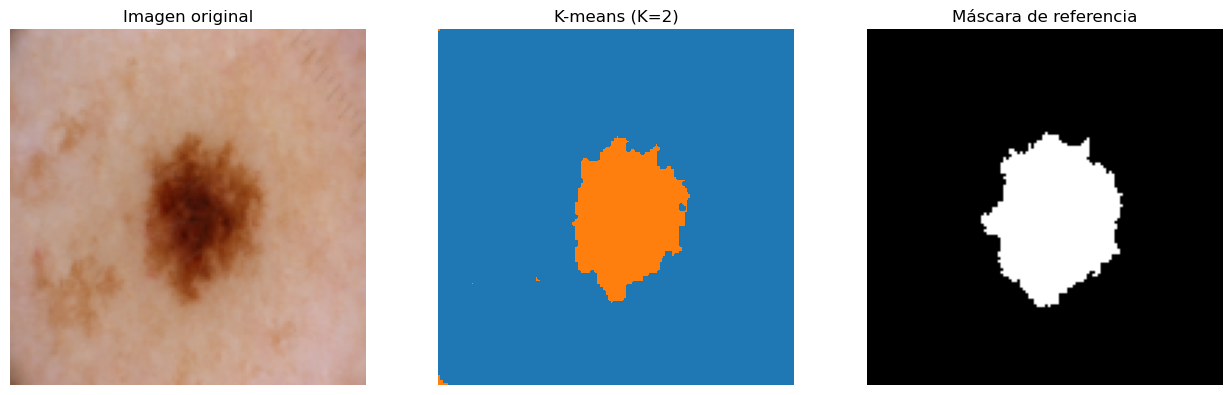

In [30]:

modelo = KMeans(
    n_clusters=mejor_k,
    random_state=42,
    n_init=5
)

etiquetas = modelo.fit_predict(X)
grupos = etiquetas.reshape(imagen.shape[:2])

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(imagen)
axes[0].set_title("Imagen original")

axes[1].imshow(grupos, cmap="tab10", vmin=0, vmax=9)
axes[1].set_title(f"K-means (K={mejor_k})")

axes[2].imshow(mascara, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Máscara de referencia")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 3. Construcción de la máscara

Tomamos como lesión el grupo con menor luminosidad promedio, porque las lesiones suelen ser más oscuras que la piel de alrededor. Este criterio puede fallar si hay sombras u otros elementos oscuros.


In [31]:

def crear_mascara(imagen, grupos):
    # Convertir imagen a valores entre 0 y 1
    imagen_normalizada = imagen.astype(float) / 255.0

    # Calcular luminosidad de cada píxel
    luminosidad = (
        0.2126 * imagen_normalizada[:, :, 0] +
        0.7152 * imagen_normalizada[:, :, 1] +
        0.0722 * imagen_normalizada[:, :, 2]
    )

    # Calcular luminosidad promedio por grupo
    promedios = {}

    for grupo in np.unique(grupos):
        promedios[grupo] = luminosidad[grupos == grupo].mean()

    # Elegir el grupo más oscuro
    grupo_lesion = min(promedios, key=promedios.get)

    # Crear máscara binaria
    mascara_predicha = (grupos == grupo_lesion).astype(np.uint8)

    return mascara_predicha, grupo_lesion


Calculamos Dice para comparar la máscara predicha con la de referencia. Un valor cercano a 1 indica mayor coincidencia.


Grupo identificado como lesión: 1
Dice: 0.9025


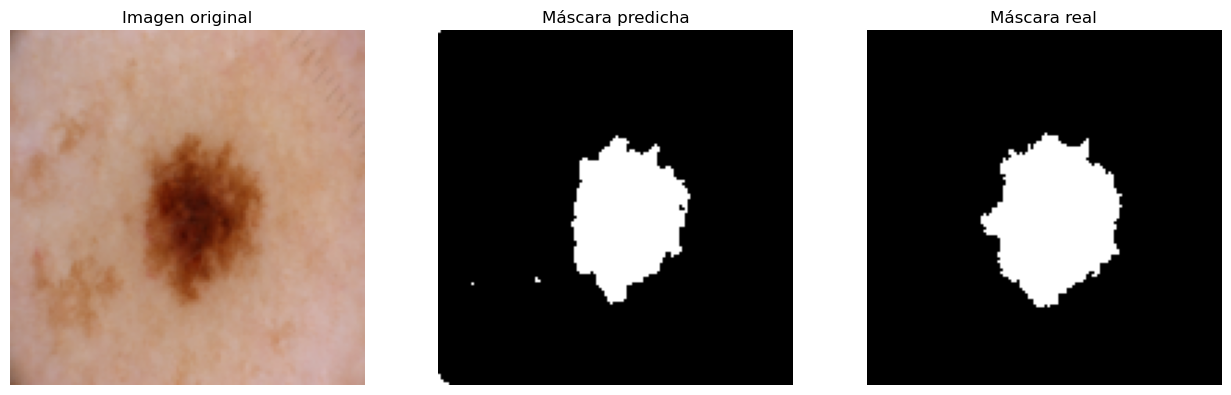

In [32]:

# Construir máscara a partir de K-means
mascara_predicha, grupo_lesion = crear_mascara(imagen, grupos)

# Calcular Dice
dice = f1_score(mascara.ravel(), mascara_predicha.ravel())

print("Grupo identificado como lesión:", grupo_lesion)
print(f"Dice: {dice:.4f}")

# Visualizar comparación
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(imagen)
axes[0].set_title("Imagen original")

axes[1].imshow(mascara_predicha, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Máscara predicha")

axes[2].imshow(mascara, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Máscara real")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 4. Ajuste de los parámetros

Evaluamos diez combinaciones de β y λ sobre las 15 imágenes de ajuste, incluidos los casos de solo color y solo posición. Comparamos Dice, V-measure y silueta; la configuración final se elige por el Dice promedio.


In [33]:

def evaluar_configuracion(id_imagen, beta, lambda_):
    # 1. Cargar imagen y máscara
    imagen, mascara_real = cargar_imagen(id_imagen, "ajuste")

    # 2. Preparar características
    pipeline.set_params(
        representacion__beta=beta,
        representacion__lambda_=lambda_
    )
    X = pipeline.fit_transform(imagen)

    # 3. Seleccionar K mediante silueta
    mejor_k, tabla_k = seleccionar_k(X)

    # 4. Aplicar K-means
    modelo = KMeans(
        n_clusters=mejor_k,
        random_state=42,
        n_init=5
    )
    etiquetas = modelo.fit_predict(X)
    grupos = etiquetas.reshape(imagen.shape[:2])

    # 5. Construir máscara automáticamente
    mascara_predicha, grupo_lesion = crear_mascara(
        imagen, grupos
    )

    # 6. Calcular métricas
    dice = f1_score(
        mascara_real.ravel(),
        mascara_predicha.ravel(),
        zero_division=0
    )

    v_measure = v_measure_score(
        mascara_real.ravel(),
        etiquetas
    )

    mejor_silueta = tabla_k["Silueta"].max()

    return {
        "Imagen": id_imagen,
        "Beta": beta,
        "Lambda": lambda_,
        "K": mejor_k,
        "Silueta": mejor_silueta,
        "Dice": dice,
        "V-measure": v_measure
    }


In [34]:

resultado = evaluar_configuracion(
    "ISIC_0000085",
    beta=1.0,
    lambda_=0.5
)

pd.DataFrame([resultado])


,Imagen,Beta,Lambda,K,Silueta,Dice,V-measure
0,ISIC_0000085,1.0,0.5,2,0.522892,0.902548,0.760299


### Configuraciones de ajuste


In [35]:

from itertools import product


# Diez configuraciones con razones distintas
configuraciones = [
    (1.0, 0.0),    # Solo color
    (1.0, 0.1),
    (1.0, 0.2),
    (1.0, 0.25),
    (1.0, 0.4),
    (1.0, 0.5),
    (1.0, 0.75),
    (1.0, 1.0),
    (1.0, 2.0),
    (0.0, 1.0)     # Solo posición
]

print("Número de configuraciones:", len(configuraciones))




Número de configuraciones: 10


In [36]:

from tqdm.auto import tqdm

# Identificadores de las 15 imágenes de ajuste
ruta_imagenes = RUTA_DATOS / "ajuste" / "imagenes"
ids_ajuste = sorted([archivo.stem for archivo in ruta_imagenes.glob("*.jpg")])

# Guardar los resultados de todos los experimentos
resultados = []

for id_imagen in tqdm(ids_ajuste, desc="Procesando imágenes"):
    for beta, lambda_ in configuraciones:
        resultado = evaluar_configuracion(id_imagen, beta, lambda_)
        resultados.append(resultado)

# Convertir resultados a DataFrame
df_resultados = pd.DataFrame(resultados)

# Guardar resultados para no repetir el proceso
df_resultados.to_csv("resultados_ajuste.csv", index=False)

print("Experimentos completados:", len(df_resultados))
display(df_resultados)


Procesando imágenes:   0%|          | 0/15 [00:00<?, ?it/s]

Experimentos completados: 150


,Imagen,Beta,Lambda,K,Silueta,Dice,V-measure
0,ISIC_0000085,1.0,0.00,2,0.792249,0.902023,0.758847
1,ISIC_0000085,1.0,0.10,2,0.763370,0.902023,0.758847
2,ISIC_0000085,1.0,0.20,2,0.708773,0.902362,0.758884
3,ISIC_0000085,1.0,0.25,2,0.678261,0.902362,0.758884
4,ISIC_0000085,1.0,0.40,2,0.584056,0.902887,0.760324
...,...,...,...,...,...,...,...
145,ISIC_0000157,1.0,0.50,2,0.552165,0.854494,0.620997
146,ISIC_0000157,1.0,0.75,5,0.466545,0.845214,0.333896
147,ISIC_0000157,1.0,1.00,5,0.472313,0.837806,0.324559
148,ISIC_0000157,1.0,2.00,5,0.456247,0.780022,0.271030


### Resumen de resultados


In [37]:

# Calcular los promedios por configuración
resumen = (
    df_resultados
    .groupby(["Beta", "Lambda"])
    .agg({
        "Dice": ["mean", "std"],
        "V-measure": "mean",
        "Silueta": "mean"
    })
    .round(4)
)

# Ordenar según Dice promedio
resumen = resumen.sort_values(
    ("Dice", "mean"),
    ascending=False
)

display(resumen)


Dice         V-measure Silueta
               mean     std      mean    mean
Beta Lambda                                  
1.0  0.50    0.8607  0.0766    0.5264  0.4970
     0.40    0.8580  0.0822    0.5384  0.5293
     0.25    0.8519  0.1017    0.6118  0.6199
     0.20    0.8513  0.1019    0.6118  0.6482
     0.00    0.8466  0.1009    0.6416  0.7510
     0.10    0.8465  0.1011    0.6415  0.7180
     0.75    0.8032  0.2323    0.3293  0.4499
     1.00    0.7696  0.2508    0.3024  0.4492
     2.00    0.7494  0.2640    0.2668  0.4335
0.0  1.00    0.2608  0.1076    0.0132  0.4072

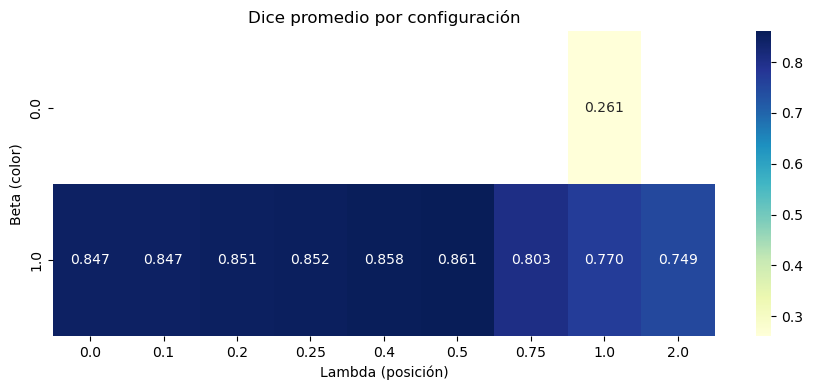

In [38]:

# Preparar tabla para visualizar Dice promedio
tabla_dice = df_resultados.pivot_table(
    index="Beta",
    columns="Lambda",
    values="Dice",
    aggfunc="mean"
)

plt.figure(figsize=(9, 4))

import seaborn as sns

sns.heatmap(
    tabla_dice,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu"
)

plt.title("Dice promedio por configuración")
plt.xlabel("Lambda (posición)")
plt.ylabel("Beta (color)")
plt.tight_layout()
plt.show()


La configuración con mayor Dice promedio de ajuste fue β = 1.0 y λ = 0.5. La usamos para la evaluación de prueba. Abajo comparamos las dos mejores configuraciones con los casos de solo color y solo posición.


In [39]:

# Configuración candidata según el Dice promedio de ajuste
mejor_beta = 1.0
mejor_lambda = 0.5

print("Beta:", mejor_beta)
print("Lambda:", mejor_lambda)

# Consultar los resultados de esta configuración
mejor_configuracion = df_resultados[
    (df_resultados["Beta"] == mejor_beta) &
    (df_resultados["Lambda"] == mejor_lambda)
]

display(mejor_configuracion)


Beta: 1.0
Lambda: 0.5


,Imagen,Beta,Lambda,K,Silueta,Dice,V-measure
5,ISIC_0000085,1.0,0.5,2,0.522892,0.902548,0.760299
15,ISIC_0000086,1.0,0.5,2,0.519651,0.931682,0.793246
25,ISIC_0000089,1.0,0.5,2,0.623441,0.940426,0.839631
35,ISIC_0000094,1.0,0.5,5,0.407251,0.884915,0.206944
45,ISIC_0000108,1.0,0.5,2,0.559291,0.910429,0.764983
55,ISIC_0000112,1.0,0.5,5,0.429323,0.770086,0.226000
65,ISIC_0000114,1.0,0.5,5,0.365656,0.743377,0.108289
75,ISIC_0000116,1.0,0.5,5,0.460926,0.745838,0.286172
85,ISIC_0000122,1.0,0.5,5,0.486798,0.888114,0.378442
95,ISIC_0000133,1.0,0.5,2,0.452673,0.739818,0.425755


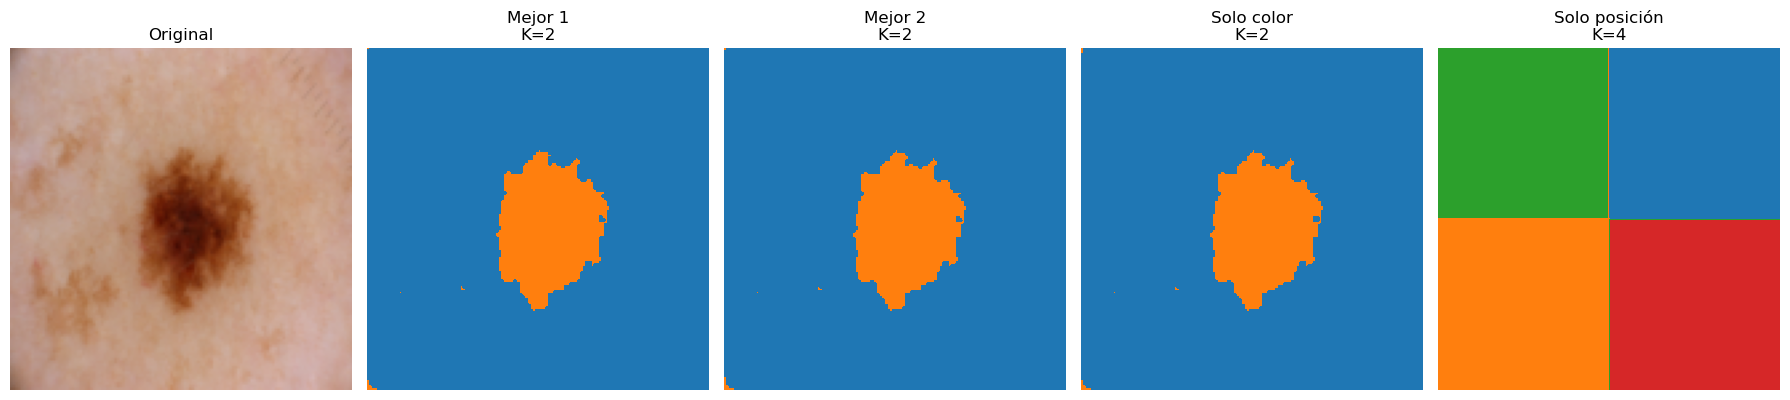

In [40]:

# Imagen de ajuste para comparar configuraciones
imagen, mascara = cargar_imagen("ISIC_0000085")

comparaciones = [
    ("Mejor 1", 1.0, 0.5),
    ("Mejor 2", 1.0, 0.4),
    ("Solo color", 1.0, 0.0),
    ("Solo posición", 0.0, 1.0)
]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

axes[0].imshow(imagen)
axes[0].set_title("Original")
axes[0].axis("off")

for i, (nombre, beta, lambda_) in enumerate(comparaciones, 1):
    pipeline.set_params(
        representacion__beta=beta,
        representacion__lambda_=lambda_
    )

    X = pipeline.fit_transform(imagen)
    k, tabla = seleccionar_k(X)

    modelo = KMeans(n_clusters=k, random_state=42, n_init=5)
    grupos = modelo.fit_predict(X).reshape(imagen.shape[:2])

    axes[i].imshow(grupos, cmap="tab10", vmin=0, vmax=9)
    axes[i].set_title(f"{nombre}\nK={k}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


## 5. Evaluación de prueba

Aplicamos el método a las cinco imágenes de prueba con β = 1.0 y λ = 0.5. Calculamos las métricas y comparamos las máscaras. Estos resultados no se usan para volver a elegir los parámetros.


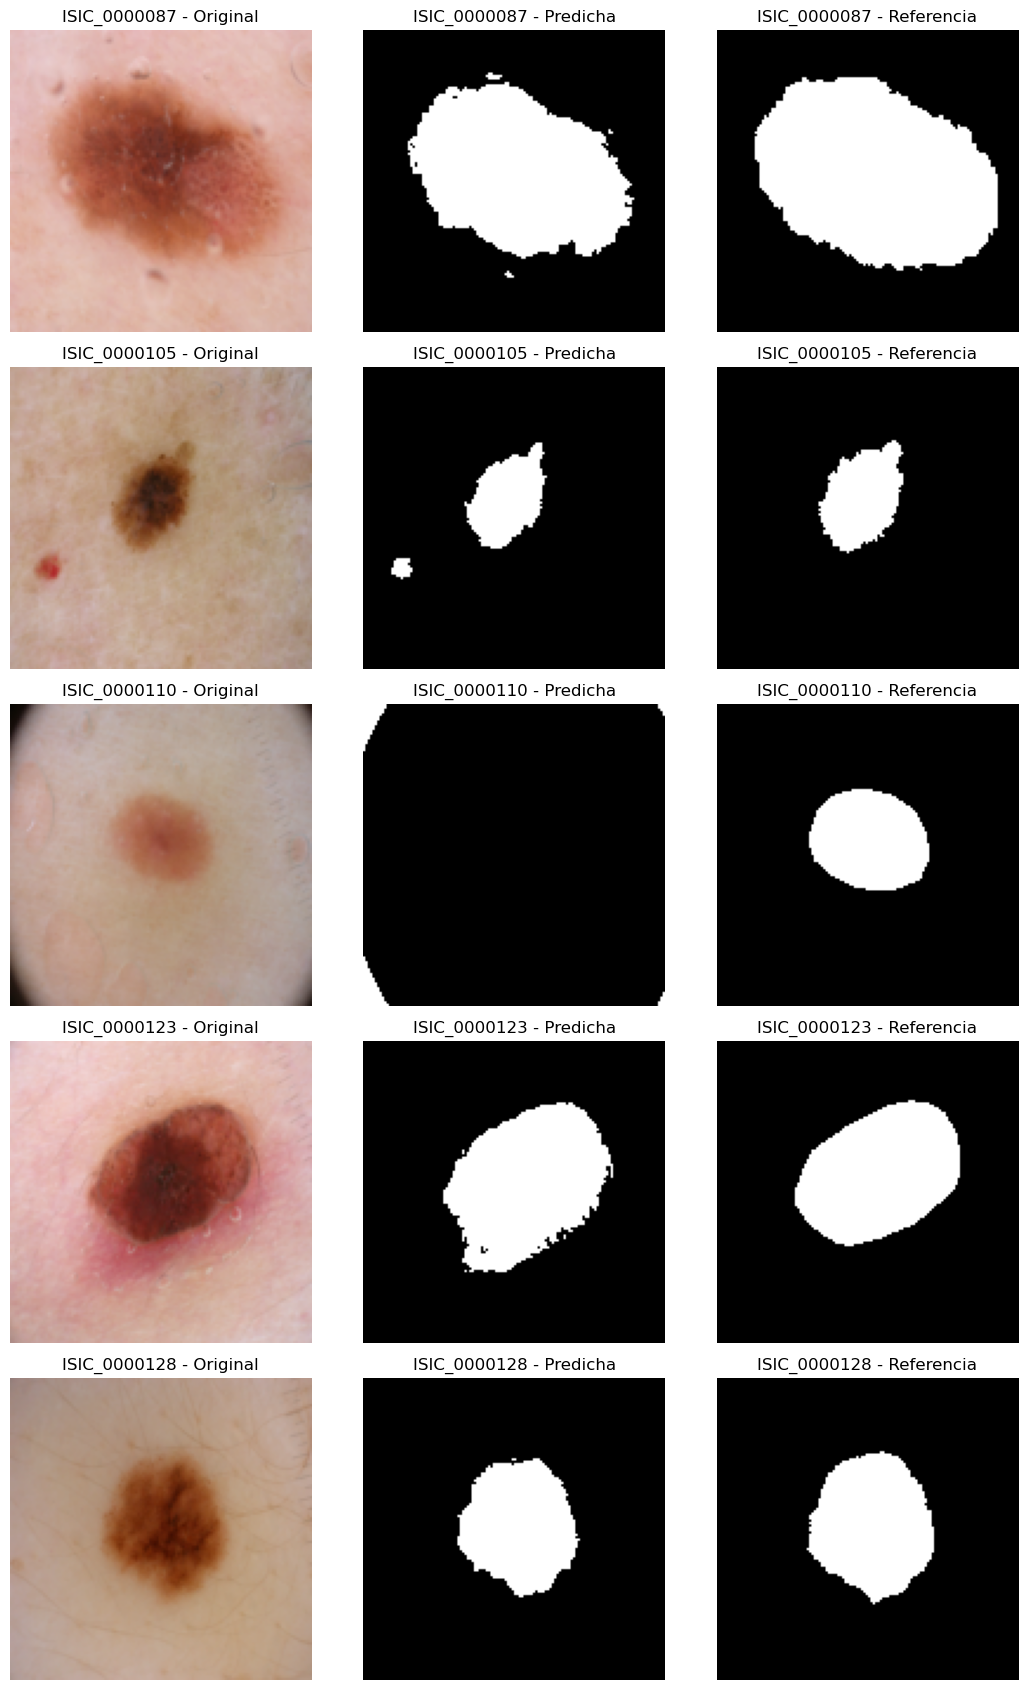

,Imagen,K,Silueta,Dice,V-measure,Precision,Recall
0,ISIC_0000087,2,0.4927,0.8821,0.6413,0.9968,0.7911
1,ISIC_0000105,5,0.4157,0.8893,0.2134,0.9423,0.8419
2,ISIC_0000110,6,0.4037,0.0000,0.1801,0.0000,0.0000
3,ISIC_0000123,2,0.5434,0.8999,0.6967,0.8509,0.9549
4,ISIC_0000128,2,0.5556,0.9329,0.8178,1.0000,0.8742


In [41]:

from sklearn.metrics import precision_score, recall_score

def evaluar_prueba(id_imagen):
    imagen, mascara_real = cargar_imagen(id_imagen, "prueba")

    pipeline.set_params(
        representacion__beta=1.0,
        representacion__lambda_=0.5
    )

    X = pipeline.fit_transform(imagen)

    k, tabla_k = seleccionar_k(X)

    modelo = KMeans(n_clusters=k, random_state=42, n_init=5)
    etiquetas = modelo.fit_predict(X)
    grupos = etiquetas.reshape(imagen.shape[:2])

    mascara_predicha, grupo_lesion = crear_mascara(imagen, grupos)

    real = mascara_real.ravel()
    predicha = mascara_predicha.ravel()

    metricas = {
        "Imagen": id_imagen,
        "K": k,
        "Silueta": tabla_k["Silueta"].max(),
        "Dice": f1_score(real, predicha, zero_division=0),
        "V-measure": v_measure_score(real, etiquetas),
        "Precision": precision_score(real, predicha, zero_division=0),
        "Recall": recall_score(real, predicha, zero_division=0)
    }

    return metricas, imagen, mascara_real, mascara_predicha


ids_prueba = sorted([
    archivo.stem
    for archivo in (RUTA_DATOS / "prueba" / "imagenes").glob("*.jpg")
])

resultados_prueba = []

fig, axes = plt.subplots(5, 3, figsize=(11, 17))

for i, id_imagen in enumerate(ids_prueba):
    metricas, imagen, real, predicha = evaluar_prueba(id_imagen)
    resultados_prueba.append(metricas)

    for j, (contenido, titulo) in enumerate([
        (imagen, "Original"),
        (predicha, "Predicha"),
        (real, "Referencia")
    ]):
        axes[i, j].imshow(
            contenido,
            cmap="gray" if j > 0 else None
        )
        axes[i, j].set_title(f"{id_imagen} - {titulo}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

df_prueba = pd.DataFrame(resultados_prueba)
display(df_prueba.round(4))


In [42]:

dice_ajuste = mejor_configuracion["Dice"].mean()
dice_prueba = df_prueba["Dice"].mean()

comparacion = pd.DataFrame({
    "Conjunto": ["Ajuste", "Prueba"],
    "Dice promedio": [dice_ajuste, dice_prueba]
})

display(comparacion.round(4))

print("Diferencia de Dice:", round(dice_ajuste - dice_prueba, 4))


,Conjunto,Dice promedio
0,Ajuste,0.8607
1,Prueba,0.7208


Diferencia de Dice: 0.1398


## 6. Análisis de resultados

### Pregunta 1

¿Qué efecto tuvo incluir la posición de los píxeles? Expliquen en qué imágenes mejoró o perjudicó la segmentación y por qué.


Tuvo un efecto positivo ya que el Dice pasó de 0.8466 con solo color a 0.8607 con λ= 0.5. Considerar la posición es importante porque las lesiones se encuentran en un punto focalizado, es decir que toda la lesión se encuentra en un área y la piel está en los alrededores y no aparecerá más de este. Esto es útil porque el modelo puede saber que, así crea que el píxel hace parte de la lesión por su color, si se encuentra muy alejado de la zona de la lesión, lo más probable es que no haga parte de ese grupo.

### Pregunta 2

¿Qué relación encontraron entre K, la silueta y el Dice? ¿Por qué estas métricas no necesariamente conducen a las mismas decisiones?

K se encarga de decir en cuantos grupos distintos vamos a separar. La silueta mide lo compactos y separados que quedaron esos grupos, mientras que el Dice mide cuanto coincide la mascara con la lesión real. Los grupos que estan mejor separados no necesariamente son los que van a representar mejor a la lesión, por ejemplo, solo color tuvo una mayor silueta promedio que fue de 0.7510, pero tuvo menor Dice que λ = 0.5, que su silueta fue de 0.4970

### Pregunta 3

¿Cómo se comparan los resultados de ajuste y prueba? ¿Por qué es importante no modificar el método después de consultar las máscaras de prueba?

El Dice promedio bajó de 0.8607 a 0.7208. El metodo funcionó peor en las imagenes nuevas, especialmente en la 110 ya que ahí tuvo un Dice de 0. No debemos modificarlo despues de haber mirado ya que seria una especie de data leakage donde el metodo va a adaptarse a los ejemplos.

### Pregunta 4

Identifiquen dos limitaciones de su modelo y expliquen sus posibles causas a partir de las imágenes y de la representación RGB + posición.

La primera sería que el grupo más oscuro puede fallar, ya que pelos o sombras pueden llegar a confundirse con la lesión, por lo que sus partes claras pueden quedar por fuera. El segundo sería que el RGB y la posición describen información bastante limitada, ya que esto no representa ni la textura ni la forma. Tambien, la iluminación puede generar que cambie los colores.

### Pregunta 5

En el contexto de DermAlpes, ¿qué consecuencias podrían tener los falsos positivos y falsos negativos? ¿Qué sesgos y problemas de generalización deben considerarse antes de utilizar el método con nuevas poblaciones o condiciones de adquisición?

Un falso positivo quiere decir que hay piel sana en la mascara, mientras que un falso negativo deja parte de la lesión por fuera. Los dos pueden cambiar la medición del tamaño y los bordes. Antes de usarlo con nuevas poblaciones, tocaría ver distintos tonos de piel, diferentes tipos de lesión, diferente iluminación, ya que los resultados son de solo 15 imagenes de ajuste, lo cual es muy poquito, por lo que no podemos garantizar el mismo desempeño en todas las personas en las que se vaya a usar.




## 7. Uso y verificación de IA generativa

Contrastamos parte de la recomendación de ChatGPT usando únicamente las imágenes de ajuste.


### Consulta realizada

Estoy diseñando un método de segmentación no supervisada para imágenes dermatoscópicas con lesiones generalmente más oscuras que la piel circundante. Represento los píxeles como [βR, βG, βB, λx, λy] con características normalizadas. ¿Qué valores de β, λ y K recomiendas explorar con K-means y cómo identificarías automáticamente los grupos de la lesión? Justifica tu recomendación y sus posibles limitaciones.


In [44]:

# Verificación de recomendación de IA
# Se utilizan exclusivamente las 15 imágenes de ajuste

from sklearn.metrics import f1_score

resultados_ia = []

ids_ajuste = sorted(
    p.stem
    for p in (RUTA_DATOS / "ajuste" / "imagenes").glob("*.jpg")
)

for id_imagen in ids_ajuste:
    img, mask_ref = cargar_imagen(id_imagen, conjunto="ajuste")

    pipeline.set_params(
        representacion__beta=1.0,
        representacion__lambda_=0.3
    )

    X_ia = pipeline.fit_transform(img)

    modelo_ia = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=5
    )

    etiquetas_ia = modelo_ia.fit_predict(X_ia)

    # Luminosidad de cada grupo (RGB normalizado)
    luminosidades = []

    for k in range(3):
        colores_grupo = X_ia[etiquetas_ia == k, :3]
        rgb_promedio = colores_grupo.mean(axis=0)

        luminosidad = (
            0.2126 * rgb_promedio[0]
            + 0.7152 * rgb_promedio[1]
            + 0.0722 * rgb_promedio[2]
        )

        luminosidades.append(luminosidad)

    grupo_lesion = int(np.argmin(luminosidades))
    mask_ia = (etiquetas_ia == grupo_lesion).astype(int)

    dice = f1_score(
        mask_ref.ravel(),
        mask_ia,
        zero_division=0
    )

    resultados_ia.append({
        "imagen": id_imagen,
        "Dice_IA": dice
    })

tabla_ia = pd.DataFrame(resultados_ia)

display(tabla_ia)

print(
    "Dice promedio recomendación IA:",
    round(tabla_ia["Dice_IA"].mean(), 4)
)


,imagen,Dice_IA
0,ISIC_0000085,0.891553
1,ISIC_0000086,0.894297
2,ISIC_0000089,0.926106
3,ISIC_0000094,0.281115
4,ISIC_0000108,0.886443
5,ISIC_0000112,0.726128
6,ISIC_0000114,0.640112
7,ISIC_0000116,0.752636
8,ISIC_0000122,0.888385
9,ISIC_0000133,0.733220


Dice promedio recomendación IA: 0.7774


### Comparación con la recomendación

ChatGPT recomendó β = 1.0, λ = 0.3 y K = 3 como punto de partida, con un rango de K entre 2 y 5. También propuso combinar oscuridad, ubicación y conectividad para identificar la lesión. La consulta se hizo sin compartir imágenes ni mencionar el conjunto de datos.

Probamos una versión simplificada: β = 1.0, λ = 0.3, K = 3 y selección del grupo de menor luminosidad. En las 15 imágenes de ajuste obtuvo un Dice promedio de 0.7774, frente a 0.8607 de la configuración seleccionada. La diferencia fue de 0.0833. Por ejemplo, obtuvo 0.9356 en ISIC_0000137 y 0.2811 en ISIC_0000094.

La recomendación fue útil como punto de partida, pero no dio el mismo resultado en todas las imágenes. Como no implementamos conectividad ni proximidad al centro, esta prueba no evalúa la propuesta completa.

La consulta fue despues del primer ajuste, así que es de una verificación retrospectiva. No se utilizó para modificar el método a partir de las imágenes de prueba. También usamos ChatGPT como apoyo para hacer esqueletos de código, ayudarnos a la interpretación de resultados y la organización del notebook.



### Aportes propios y aprendizajes

Ejecutamos los experimentos en nuestro entorno y revisamos las tablas y visualizaciones obtenidas. Contrastamos las sugerencias con las máscaras de referencia y sustentamos la configuración final, β = 1.0 y λ = 0.5, en el Dice promedio de ajuste. El código y parte de las explicaciones recibieron apoyo de ChatGPT.

Durante el proceso revisamos las diez combinaciones para evitar pesos relativos equivalentes y actualizamos las visualizaciones y el texto para que coincidieran con los resultados. Mantuvimos la configuración final durante la evaluación de prueba.

Aprendimos que incluir posición puede ayudar, pero darle demasiado peso puede perjudicar la segmentación. También entendimos que la silueta evalúa los grupos y Dice evalúa la máscara, y que las recomendaciones de IA necesitan comprobación experimental antes de aceptarse.

### Ejemplos de prompts usados

Ayúdame a organizar los Markdown del notebook con títulos y explicaciones breves, tomando como base mi análisis y los resultados

Ayúdame a entender qué significa K en K-means y qué mide el coeficiente de silueta.

Ayúdame dandome el esqueleto de codigo para poder hacer el pipeline con la representación de los pixeles


## Bonos

### Bono A. Visualización con PCA

Usamos la imagen de ajuste ISIC_0000085 con β = 1.0 y λ = 0.5. Proyectamos una muestra reproducible de 2000 píxeles en dos componentes y la coloreamos por clúster y por máscara real.


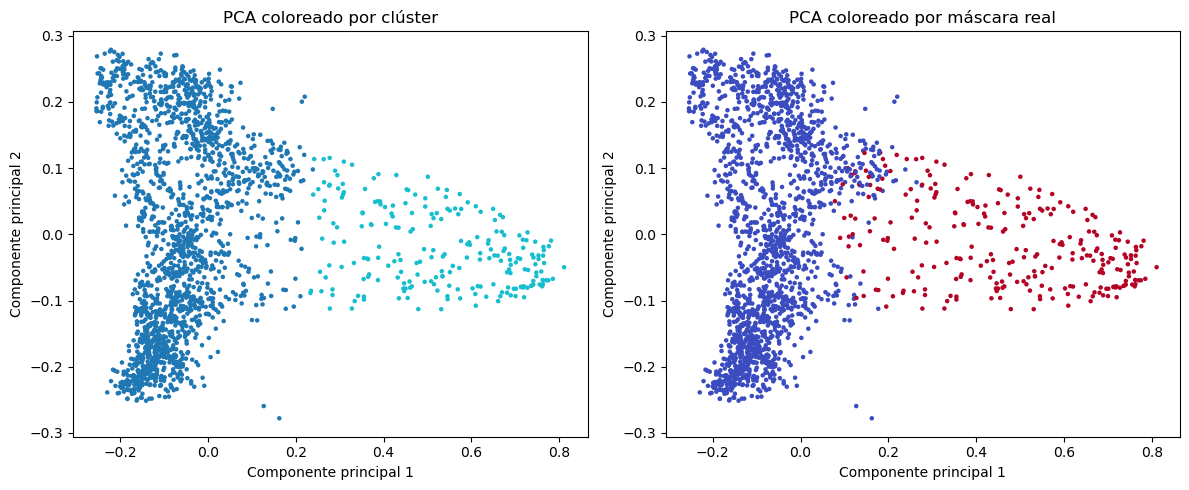

Varianza explicada: 0.7595566142502144


In [43]:

from sklearn.decomposition import PCA

# Usar exclusivamente una imagen de ajuste
imagen, mascara = cargar_imagen("ISIC_0000085")

# Configuración seleccionada en ajuste
pipeline.set_params(
    representacion__beta=1.0,
    representacion__lambda_=0.5
)

X = pipeline.fit_transform(imagen)

# Seleccionar una muestra reproducible de 2000 píxeles
rng = np.random.default_rng(42)
indices = rng.choice(len(X), size=2000, replace=False)

X_muestra = X[indices]
mascara_muestra = mascara.ravel()[indices]

# K-means sobre todos los píxeles
k, _ = seleccionar_k(X)

modelo = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=5
)

etiquetas = modelo.fit_predict(X)
grupos_muestra = etiquetas[indices]

# PCA a dos componentes
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_muestra)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=grupos_muestra,
    cmap="tab10",
    s=5
)
axes[0].set_title("PCA coloreado por clúster")

axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=mascara_muestra,
    cmap="coolwarm",
    s=5
)
axes[1].set_title("PCA coloreado por máscara real")

for ax in axes:
    ax.set_xlabel("Componente principal 1")
    ax.set_ylabel("Componente principal 2")

plt.tight_layout()
plt.show()

print(
    "Varianza explicada:",
    pca.explained_variance_ratio_.sum()
)


Las dos componentes explican el 75.96 % de la varianza. En las gráficas se observa que uno de los clústeres coincide en buena parte con los píxeles de la lesión, aunque hay superposición en la zona de transición.

PCA permite ver parte de la separación entre los grupos, pero deja fuera el 24.04 % de la varianza. Por eso, la proyección no muestra toda la estructura de las cinco características ni garantiza que los bordes de la máscara sean correctos.


### Bono B. Comparación con Mean Shift

Mean Shift agrupa los puntos alrededor de zonas de mayor densidad. No requiere fijar K, pero depende del ancho de banda: valores pequeños suelen producir más grupos y valores grandes pueden unirlos.

Lo comparamos con K-means sobre ISIC_0000085 a 64 × 64 píxeles. Ambos usan β = 1.0, λ = 0.5 y el grupo de menor luminosidad para construir la máscara.


Bandwidth estimado: 0.2296


,Algoritmo,Clústeres,Dice,Tiempo (s)
0,K-means,2,0.909474,0.431751
1,Mean Shift,3,0.916493,0.205167


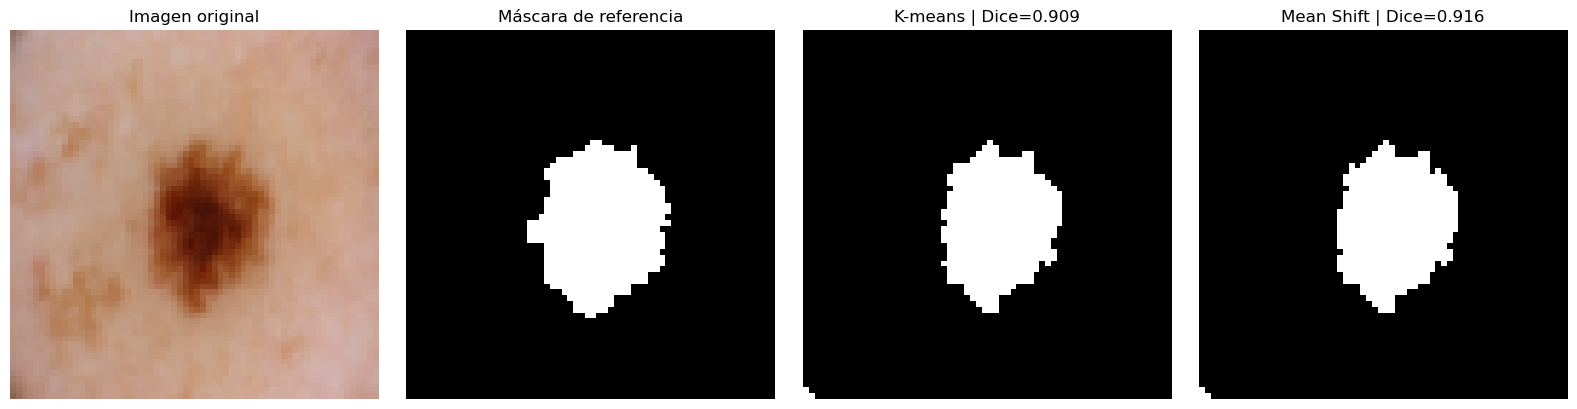

In [45]:

import time
from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.metrics import f1_score

# 1. Cargar una imagen de ajuste a resolución reducida
id_imagen = "ISIC_0000085"

imagen_b, mascara_b = cargar_imagen(
    id_imagen,
    conjunto="ajuste",
    tamaño=(64, 64)
)

# 2. Obtener las características RGB + posición
pipeline.set_params(
    representacion__beta=1.0,
    representacion__lambda_=0.5
)

X_b = pipeline.fit_transform(imagen_b)


# 3. Función para construir la máscara
# Seleccionamos el grupo con menor luminosidad promedio
def mascara_por_luminosidad(imagen, etiquetas):
    colores = imagen.reshape(-1, 3) / 255.0

    luminosidades = []

    for grupo in np.unique(etiquetas):
        rgb = colores[etiquetas == grupo].mean(axis=0)

        luminosidad = (
            0.2126 * rgb[0]
            + 0.7152 * rgb[1]
            + 0.0722 * rgb[2]
        )

        luminosidades.append((grupo, luminosidad))

    grupo_lesion = min(
        luminosidades,
        key=lambda x: x[1]
    )[0]

    return (etiquetas == grupo_lesion).reshape(imagen.shape[:2])


# 4. K-means: seleccionar K por silueta
inicio = time.perf_counter()

mejor_k_b, tabla_k_b = seleccionar_k(X_b)

modelo_kmeans = KMeans(
    n_clusters=mejor_k_b,
    random_state=42,
    n_init=5
)

etiquetas_kmeans = modelo_kmeans.fit_predict(X_b)

tiempo_kmeans = time.perf_counter() - inicio

mascara_kmeans = mascara_por_luminosidad(
    imagen_b, etiquetas_kmeans
)

dice_kmeans = f1_score(
    mascara_b.ravel(),
    mascara_kmeans.ravel(),
    zero_division=0
)


# 5. Mean Shift: estimar bandwidth
inicio = time.perf_counter()

bandwidth = estimate_bandwidth(
    X_b,
    quantile=0.2,
    n_samples=500,
    random_state=42
)

# Evitar un bandwidth nulo
bandwidth = max(float(bandwidth), 0.01)

modelo_meanshift = MeanShift(
    bandwidth=bandwidth,
    bin_seeding=True
)

etiquetas_meanshift = modelo_meanshift.fit_predict(X_b)

tiempo_meanshift = time.perf_counter() - inicio

mascara_meanshift = mascara_por_luminosidad(
    imagen_b, etiquetas_meanshift
)

dice_meanshift = f1_score(
    mascara_b.ravel(),
    mascara_meanshift.ravel(),
    zero_division=0
)


# 6. Comparar resultados
tabla_bono_b = pd.DataFrame([
    {
        "Algoritmo": "K-means",
        "Clústeres": mejor_k_b,
        "Dice": dice_kmeans,
        "Tiempo (s)": tiempo_kmeans
    },
    {
        "Algoritmo": "Mean Shift",
        "Clústeres": len(np.unique(etiquetas_meanshift)),
        "Dice": dice_meanshift,
        "Tiempo (s)": tiempo_meanshift
    }
])

print("Bandwidth estimado:", round(bandwidth, 4))
display(tabla_bono_b)


# 7. Visualizaciones
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(imagen_b)
axes[0].set_title("Imagen original")

axes[1].imshow(mascara_b, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Máscara de referencia")

axes[2].imshow(mascara_kmeans, cmap="gray", vmin=0, vmax=1)
axes[2].set_title(f"K-means | Dice={dice_kmeans:.3f}")

axes[3].imshow(mascara_meanshift, cmap="gray", vmin=0, vmax=1)
axes[3].set_title(f"Mean Shift | Dice={dice_meanshift:.3f}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


El ancho de banda estimado fue 0.2296, a partir de una muestra reproducible de 500 píxeles.

| Método | Clústeres | Dice | Tiempo (s) |
| --- | --- | --- | --- |
| K-means | 2 | 0.9095 | 0.4318 |
| Mean Shift | 3 | 0.9165 | 0.2052 |

En esta imagen, Mean Shift obtuvo un Dice ligeramente mayor, con una diferencia de 0.007, y tardó menos. Ambas máscaras recuperaron gran parte de la lesión y mostraron pequeñas diferencias en los bordes.

Los tiempos incluyen la búsqueda de K en K-means y la estimación del ancho de banda en Mean Shift. Como solo probamos una imagen a resolución reducida, no podemos afirmar que Mean Shift sea siempre mejor o más rápido. Además, ambos métodos necesitan un criterio adicional para decidir qué grupo representa la lesión.
